In [36]:
!python --version
!echo Code by: Tanvir Anjom Siddique

Python 3.13.5
Code by: Tanvir Anjom Siddique


# Outlier Detection and Handling in Tabular Data

## Objective
This notebook explains, how to identify and treat outliers in tabular datasets using statistical approaches. Each method includes intuition, working principle, and suitability.

### What is an outlier?
Outliers are data points that differ significantly from other observations. They can skew analysis, affect model performance, and indicate data entry errors or rare events.

In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import RobustScaler

In [38]:
df = sns.load_dataset('titanic')
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [39]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [40]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


## Visualization
### How it works
Boxplots display median, quartiles, and extreme values. Points outside whiskers indicate potential outliers.
### Suitable
Initial exploration
### Not suitable
High dimensional precise detection

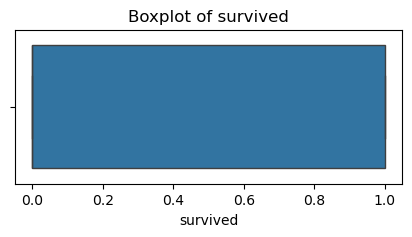

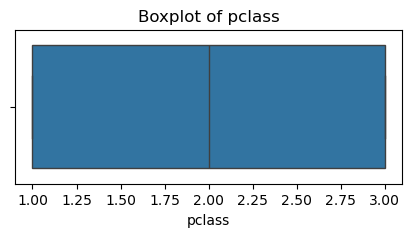

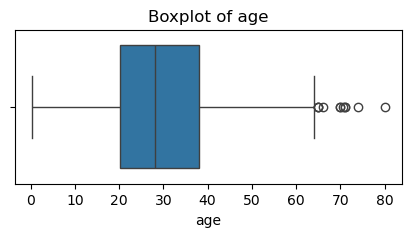

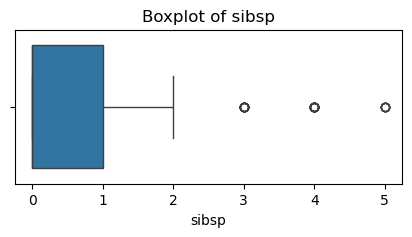

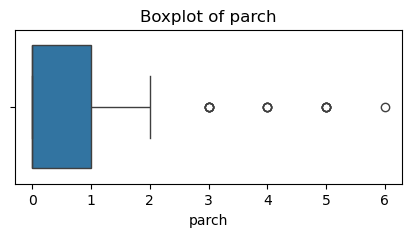

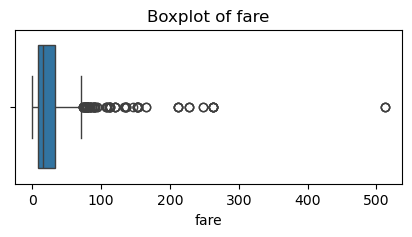

In [41]:
df_num = df.select_dtypes(include=np.number).dropna()
# display(df_num.head())
# display(df_num.columns)
# sns.boxplot(x=df_num['survived'])
for col in df_num.columns:
    plt.figure(figsize=(5,2))
    sns.boxplot(x=df_num[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

## Boxplot Components and Interpretation

### Boxplot Components
- **Box**: from Q1 (25th percentile) to Q3 (75th percentile)  
- **Median line**: inside the box  
- **Whiskers**: extend to Q1 - 1.5*IQR and Q3 + 1.5*IQR by default  
- **Outliers**: points beyond whiskers are plotted individually  

### Why Some Boxes Look Strange
- If the column is **highly skewed** (like `fare` in Titanic), most values are concentrated near one end and a few large values stretch the whisker. The box may appear very small.  
- If the column has **few unique values** (like `parch` or `sibsp`), the quartiles may coincide, so the box collapses into a line.  
- If you **log-transform** a column, extreme outliers shrink, making the box more readable, but whiskers may not appear “extreme” as expected.  

### How to Fix / Improve Interpretation
- Use **raw values** for small-range numeric features (like `parch`, `sibsp`) so the box shows actual min, max, and median.  
- Use **log-transform** only for highly skewed columns (like `fare`) to better visualize whiskers and outliers.  
- Show **actual min/max as text or overlay points** for clarity.  

### Robust Visualization
This method shows **min, Q1, median, Q3, max, and outliers explicitly**:

#### What This Does
- Shows a proper **box (Q1–Q3) and whiskers (1.5*IQR)**.  
- Red dot → **min**, Blue dot → **max**, Green dot → **median**.  
- Outliers remain visible beyond whiskers.  
- Skewed features are **log-transformed** for better visualization.  

Using this approach, students can **see the true extremes, median, and box components clearly**, even if the data is skewed or has few unique values.

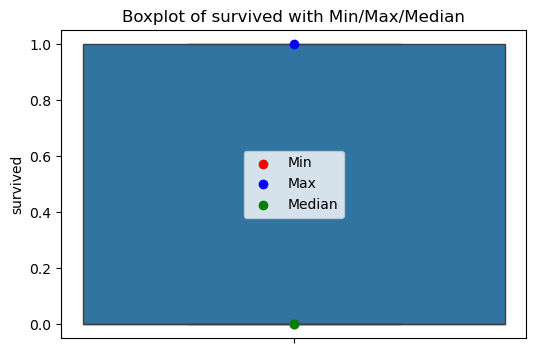

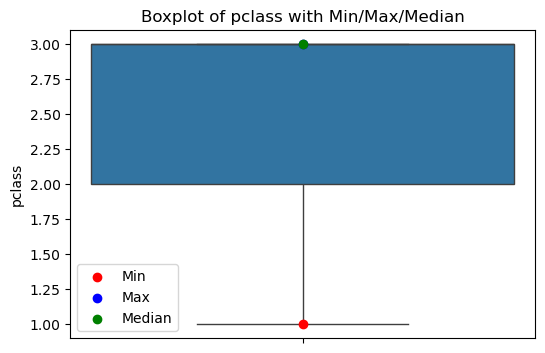

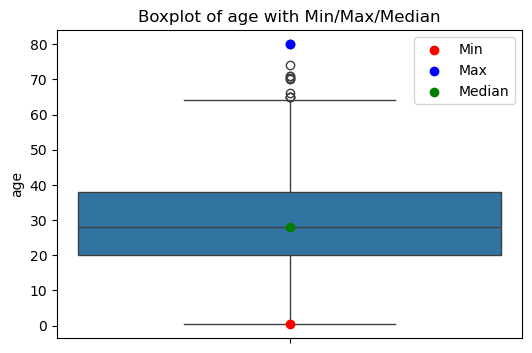

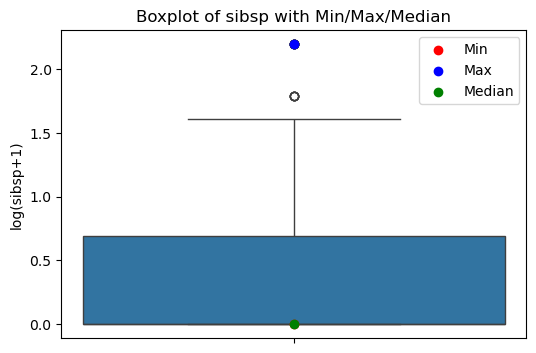

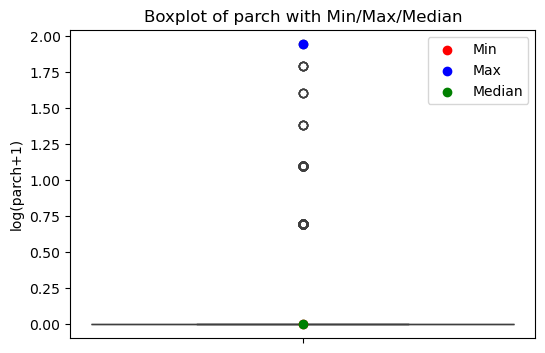

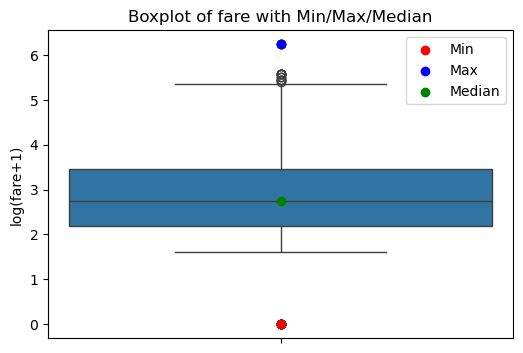

In [42]:
df_num = df.select_dtypes(include=np.number)

for col in df_num.columns:
    data = df_num[col].dropna()
    
    plt.figure(figsize=(6,4))
    
    # Log-transform only for skewed columns
    if data.skew() > 1:
        data_plot = np.log1p(data)
        plt.ylabel(f"log({col}+1)")
    else:
        data_plot = data
        plt.ylabel(col)
    
    sns.boxplot(y=data_plot, showfliers=True)
    
    # Overlay actual min/max and median
    plt.scatter([0], [data_plot.min()], color='red', label='Min', zorder=5)
    plt.scatter([0], [data_plot.max()], color='blue', label='Max', zorder=5)
    plt.scatter([0], [data_plot.median()], color='green', label='Median', zorder=5)
    
    plt.title(f"Boxplot of {col} with Min/Max/Median")
    plt.legend()
    plt.show()

## Z-Score Method
### How it works
Measures distance from mean using standard deviation. Values beyond ±3 are outliers.
### Suitable
Normal data
### Not suitable
Skewed data
### Formula
z = (x - μ) / σ
- x = data point
- μ = mean
- σ = standard deviation
Interpretation:
- z ≈ 0 → near mean
- |z| > 3 → likely outlier

In [43]:
z_scores = np.abs(stats.zscore(df_num))
outliers_z = np.where(z_scores > 3)

## IQR Method
### How it works
Uses quartiles and IQR to detect extreme values.
### Suitable
Most real-world data
### Not suitable
Very small datasets

In [44]:
def detect_iqr(df):
    outliers = []
    for col in df.columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        idx = df[(df[col] < lower) | (df[col] > upper)].index
        outliers.extend(idx)
    return list(set(outliers))

iqr_outliers = detect_iqr(df_num)

## Percentile Method
### How it works
Removes extreme values using percentile thresholds (e.g., 1%-99%).
### Suitable
Large datasets
### Not suitable
Small datasets or when rare values matter
### Formula
Lower Bound = Q_p
Upper Bound = Q_{1-p}
- Example: 1% → lower bound, 99% → upper bound
- Values outside these bounds are outliers

In [45]:
def detect_percentile(df, low=0.01, high=0.99):
    outliers = []
    for col in df.columns:
        l = df[col].quantile(low)
        h = df[col].quantile(high)
        idx = df[(df[col] < l) | (df[col] > h)].index
        outliers.extend(idx)
    return list(set(outliers))

percentile_outliers = detect_percentile(df_num)

## Removing Outliers
### Idea
Delete rows containing outliers.
### Suitable
Large datasets
### Not suitable
Small datasets

In [46]:
df_removed = df_num.drop(index=iqr_outliers)

## IQR-Based Capping
### Idea
Limit extreme values using IQR boundaries.
### Suitable
Most datasets

In [47]:
def cap_iqr(df):
    new_df = df.copy()
    for col in df.columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        new_df[col] = np.where(df[col] < lower, lower,
                               np.where(df[col] > upper, upper, df[col]))
    return new_df

df_capped_iqr = cap_iqr(df_num)

## Percentile-Based Capping
### Idea
Cap values using fixed percentile thresholds.
### Suitable
Large datasets

In [48]:
def cap_percentile(df, low=0.01, high=0.99):
    new_df = df.copy()
    for col in df.columns:
        lower = df[col].quantile(low)
        upper = df[col].quantile(high)
        new_df[col] = np.where(df[col] < lower, lower,
                               np.where(df[col] > upper, upper, df[col]))
    return new_df

df_capped_percentile = cap_percentile(df_num)

## Median Replacement (Numerical)
### How it works
Replaces outliers with median value.
### Suitable
Skewed data

In [ ]:
def replace_median(df):
    new_df = df.copy()
    for col in df.columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        median = df[col].median()
        new_df[col] = np.where((df[col] < lower) | (df[col] > upper), median, df[col])
    return new_df
df_median = replace_median(df_num)

## Mean Replacement (Numerical)
### How it works
Replaces outliers with mean value.
### Suitable
Normal symmetric data
### Not suitable
Skewed data

In [50]:
def replace_mean(df):
    new_df = df.copy()
    for col in df.columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        mean = df[col].mean()
        new_df[col] = np.where((df[col] < lower) | (df[col] > upper), mean, df[col])
    return new_df

df_mean = replace_mean(df_num)

## Robust Scaling
### How it works
Uses median and IQR for scaling instead of mean and std.
### Formula
x_scaled = (x - median) / IQR
- median = 50th percentile
- IQR = Q3 - Q1
### Suitable
Data with many outliers
### Not suitable
Clean, normally distributed data

In [52]:
scaler = RobustScaler()
df_scaled = scaler.fit_transform(df_capped_iqr)

## Final Note
Use IQR for detection and capping as default. Use median for numerical data, mean for symmetric data, and mode for categorical data.